# 01 · Datos, features causales, folds y normalizador

Notebook de demostración de la parte 01 (`code/data.py`). Solo importa funciones del módulo y muestra resultados;
el pipeline evaluado es `python main.py`. Guía: `docs/instrucciones/01_datos_features.md`.

In [1]:
import sys
sys.path.insert(0, "..")
sys.modules.pop("code", None)  # IPython ya importó el módulo `code` estándar (ver docs/decisiones.md)

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from code import data
from main import BTC_CSV, FOLDS

## 1. Carga, limpieza y validación

`load_ohlcv` lee el CSV de CryptoDataDownload, convierte las marcas de tiempo (la columna `Unix` mezcla milisegundos
y microsegundos desde 2025), quita duplicados, redondea las barras desfasadas de febrero de 2018 y valida OHLC.

In [2]:
ohlcv, report = data.load_ohlcv(BTC_CSV)
print(json.dumps(report, indent=1))
ohlcv.head()

{
 "rows_read": 75588,
 "duplicates_removed": 506,
 "off_hour_bars_floored": 43,
 "bars": 75082,
 "first_bar": "2017-08-17 04:00:00+00:00",
 "last_bar": "2026-04-26 23:00:00+00:00",
 "hours_in_range": 76196,
 "missing_hours": 1114,
 "missing_hours_by_year": {
  "2017": 7,
  "2018": 61,
  "2019": 28,
  "2020": 17,
  "2021": 13,
  "2023": 1,
  "2025": 687,
  "2026": 300
 },
 "missing_midnight_bars": 374,
 "longest_gap_hours": 145,
 "zero_volume_bars": 4,
 "rows_stated_in_assignment": 75558
}


,open,high,low,close,volume_btc,volume_usdt,trades,gap_hours
datetime,,,,,,,,
2017-08-17 04:00:00+00:00,4261.48,4313.62,4261.32,4308.83,47.181009,202366.138393,171,0
2017-08-17 05:00:00+00:00,4308.83,4328.69,4291.37,4315.32,23.234916,100304.823567,102,0
2017-08-17 06:00:00+00:00,4330.29,4345.45,4309.37,4324.35,7.229691,31282.312670,36,0
2017-08-17 07:00:00+00:00,4316.62,4349.99,4287.41,4349.99,4.443249,19241.058300,25,0
2017-08-17 08:00:00+00:00,4333.32,4377.85,4333.32,4360.69,0.972807,4239.503586,28,0


**Horas faltantes.** No se inventan barras: la columna `gap_hours` dice cuántas horas faltan antes de cada barra.
En 2025–2026 falta la barra de las 00:00 en la mayoría de los días y hay huecos de varios días; en esas horas el precio
sí se movió (la apertura siguiente brinca respecto al último cierre), así que el entorno las trata como un gap.

In [3]:
gaps = ohlcv.loc[ohlcv["gap_hours"] > 0, "gap_hours"]
print("barras precedidas por un hueco:", len(gaps))
print(gaps.groupby(gaps.index.year).agg(["count", "sum", "max"]).rename(columns={"count": "huecos", "sum": "horas", "max": "más largo"}))
jump = np.log(ohlcv["open"] / ohlcv["close"].shift())
print("\n|apertura / cierre previo| mediano: contiguas", round(jump[ohlcv.gap_hours == 0].abs().median(), 6),
      "· tras 1 h faltante", round(jump[ohlcv.gap_hours == 1].abs().median(), 6))

barras precedidas por un hueco: 376
          huecos  horas  más largo
datetime                          
2017           1      7          7
2018           7     61         32
2019           5     28         10
2020           8     17          5
2021           6     13          4
2023           1      1          1
2025         240    687        145
2026         108    300         73

|apertura / cierre previo| mediano: contiguas 0.0 · tras 1 h faltante 0.002149


## 2. Features causales por familia

Cada feature de la fila t usa solo barras con marca ≤ t. Las familias son las unidades de la ablación de la parte 07.

In [4]:
features = data.compute_features(ohlcv)
pd.DataFrame([(fam, ", ".join(cols)) for fam, cols in data.FEATURE_FAMILIES.items()], columns=["familia", "features"])

,familia,features
0,returns,"ret_1h, ret_4h, ret_24h, ret_168h"
1,volatility,"rv_24h, rv_168h, parkinson_24h, vol_ratio_24_168"
2,trend,"ema_gap_24h, ema_gap_168h, ema_gap_720h, drawd..."
3,volume,"volume_z_168h, volume_ratio_24_168"
4,calendar,"hour_sin, hour_cos, dow_sin, dow_cos"
5,belief,"belief_drift, belief_drift_se, belief_drift_t,..."


In [5]:
features.dropna().describe().T[["mean", "std", "min", "max"]].round(4)

,mean,std,min,max
ret_1h,0.0000,0.0077,-0.2010,0.1603
ret_4h,0.0002,0.0147,-0.3429,0.1823
ret_24h,0.0010,0.0359,-0.6245,0.2987
ret_168h,0.0066,0.0951,-0.7810,0.5784
rv_24h,0.0062,0.0046,0.0000,0.0771
rv_168h,0.0066,0.0039,0.0015,0.0360
parkinson_24h,0.0067,0.0047,0.0005,0.0781
vol_ratio_24_168,0.9375,0.3711,0.0069,2.6703
ema_gap_24h,0.0005,0.0169,-0.3224,0.2075
ema_gap_168h,0.0033,0.0469,-0.4688,0.4029


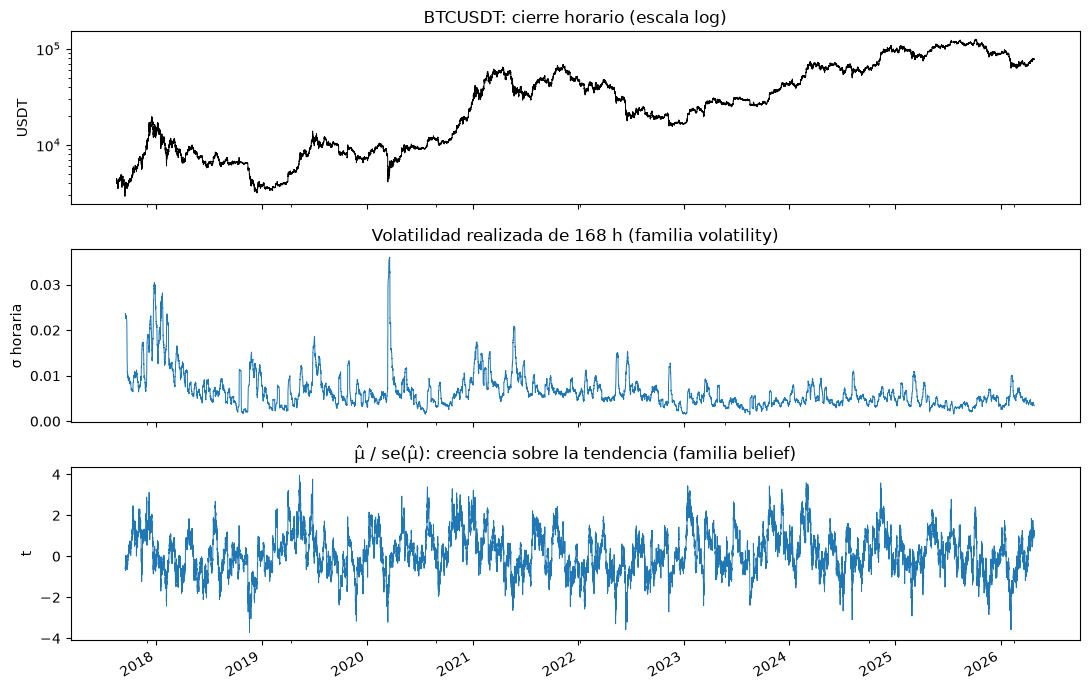

In [6]:
fig, ax = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
ohlcv["close"].plot(ax=ax[0], logy=True, color="k", lw=0.7, title="BTCUSDT: cierre horario (escala log)")
features["rv_168h"].plot(ax=ax[1], lw=0.7, title="Volatilidad realizada de 168 h (familia volatility)")
features["belief_drift_t"].plot(ax=ax[2], lw=0.7, title="μ̂ / se(μ̂): creencia sobre la tendencia (familia belief)")
for a in ax: a.set_xlabel("")
ax[0].set_ylabel("USDT"); ax[1].set_ylabel("σ horaria"); ax[2].set_ylabel("t")
plt.tight_layout(); plt.show()

## 3. Folds de walk-forward (§3.6) y normalizador por fold

Cada fold tiene su normalizador, ajustado **solo** con su entrenamiento y aplicado sin cambios a validación y prueba.
Por eso en validación y prueba las medias no son 0 ni las desviaciones 1: el mercado cambió respecto al train.

In [7]:
pd.DataFrame({(k, name): v for k, parts in data.describe_folds(ohlcv, features, FOLDS).items()
              for name, v in parts.items()}).T

start                        end   bars  \
1 train       2017-09-16 11:00:00+00:00  2021-12-31 23:00:00+00:00  37502   
  validation  2022-01-01 00:00:00+00:00  2022-12-31 23:00:00+00:00   8760   
  test        2023-01-01 00:00:00+00:00  2023-12-31 23:00:00+00:00   8759   
2 train       2017-09-16 11:00:00+00:00  2022-12-31 23:00:00+00:00  46262   
  validation  2023-01-01 00:00:00+00:00  2023-12-31 23:00:00+00:00   8759   
  test        2024-01-01 00:00:00+00:00  2024-12-31 23:00:00+00:00   8784   
3 train       2017-09-16 11:00:00+00:00  2023-12-31 23:00:00+00:00  55021   
  validation  2024-01-01 00:00:00+00:00  2024-12-31 23:00:00+00:00   8784   
  test        2025-01-01 00:00:00+00:00  2025-12-31 23:00:00+00:00   8073   
4 train       2017-09-16 11:00:00+00:00  2024-12-31 23:00:00+00:00  63805   
  validation  2025-01-01 00:00:00+00:00  2025-12-31 23:00:00+00:00   8073   
  test        2026-01-01 01:00:00+00:00  2026-04-26 23:00:00+00:00   2484   

             missing_hours  
1 train                119  
  validation             0  
  test                   1  
2 train                119  
  validation             1  
  test                   0  
3 train                120  
  validation             0  
  test                 687  
4 train                120  
  validation           687  
  test                 299

In [8]:
rows = []
for k in FOLDS:
    fold = data.build_fold_dataset(ohlcv, features, k, FOLDS[k])
    for name, z in fold.features.items():
        rows.append({"fold": k, "partición": name, "barras": len(z),
                     "|media| máx.": z.mean().abs().max(), "desv. mín.": z.std().min(), "desv. máx.": z.std().max(),
                     "% recortado a ±5": 100 * (z.abs() >= data.CLIP_Z).mean().mean()})
pd.DataFrame(rows).round(3)

,fold,partición,barras,|media| máx.,desv. mín.,desv. máx.,% recortado a ±5
0,1,train,37502,0.009,0.927,1.000,0.144
1,1,validation,8760,0.574,0.440,1.136,0.008
2,1,test,8759,0.980,0.264,1.381,0.011
3,2,train,46262,0.009,0.928,1.000,0.149
4,2,validation,8759,0.957,0.282,1.345,0.009
5,2,test,8784,0.674,0.274,1.399,0.007
6,3,train,55021,0.010,0.923,1.000,0.162
7,3,validation,8784,0.528,0.277,1.316,0.008
8,3,test,8073,0.744,0.343,1.317,0.005
9,4,train,63805,0.010,0.924,1.000,0.170


## 4. Causalidad (prueba obligatoria 2)

Recalcular las features con los datos hasta la barra i da exactamente la fila i del cálculo sobre la serie completa
(`tests/test_causality.py`).

In [9]:
i = 5_000
truncated = data.compute_features(ohlcv.iloc[: i + 1]).iloc[-1]
print("máxima diferencia absoluta:", float(np.abs(truncated - features.iloc[i]).max()))

máxima diferencia absoluta: 0.0
